# How assumptions narrow the effect region

## Regions Defined by Assumptions

A partially identified effect is represented by a set rather than one number. With supplied outcome limits $L$ and $U$, write the empirical identification region as

$$
\mathcal I(L,U)=[\underline\tau(L,U),\overline\tau(L,U)].
$$

The set $\mathcal I(L,U)$ contains every empirical average effect consistent with the observed outcomes, consistency, and the supplied limits. Changing $L$ or $U$ changes the assumption and therefore changes the set. It does not add new observations.

### Group Decomposition

Let $p$ be the treated fraction, $\bar Y_1^{\mathrm{obs}}$ the mean observed outcome among treated units, and $\bar Y_0^{\mathrm{obs}}$ the mean observed outcome among control units. The limits can be written as

$$
\underline\tau=p(\bar Y_1^{\mathrm{obs}}-U)+(1-p)(L-\bar Y_0^{\mathrm{obs}}),
$$

and

$$
\overline\tau=p(\bar Y_1^{\mathrm{obs}}-L)+(1-p)(U-\bar Y_0^{\mathrm{obs}}).
$$

These expressions separate the treated and control contributions. They also show that the observed group means determine the location of the interval, while the assumed outcome range determines its width.

Row,Symbol,Description
,String,String
1,"I(L,U)",Identification region under supplied outcome limits
2,p,Fraction of units in the treated group
3,Mean observed Y among treated,Observed treated-group outcome mean
4,Mean observed Y among control,Observed control-group outcome mean
5,Lower tau,Lower endpoint of the empirical effect region
6,Upper tau,Upper endpoint of the empirical effect region


Row,Calculation,Supplied information,Not supplied
,String,String,String
1,Worst-case effect region,Consistency and finite outcome limits,Exchangeability and sampling distribution
2,Regression sensitivity,Linear regression and two partial R-squared values,Identity or existence of an omitted variable
3,Observed-covariate benchmark,Measured baseline variables,Upper bound on all hidden confounding
4,Public county example,Fixed public outcomes and group labels,A defended causal assignment mechanism


Row,Endpoint,Treated contribution,Control contribution,Total
,String,Float64,Float64,Float64
1,Lower,-0.196,-0.362,-0.558
2,Upper,0.186,0.256,0.442


Row,Padding beyond observed range,Lower outcome limit,Upper outcome limit,Lower effect limit,Upper effect limit,Region width
,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0,-1.52558,0.969401,-1.32938,1.16561,2.49498
2,0.05,-1.57558,1.0194,-1.37938,1.21561,2.59498
3,0.1,-1.62558,1.0694,-1.42938,1.26561,2.69498
4,0.15,-1.67558,1.1194,-1.47938,1.31561,2.79498
5,0.2,-1.72558,1.1694,-1.52938,1.36561,2.89498
6,0.25,-1.77558,1.2194,-1.57938,1.41561,2.99498
7,0.3,-1.82558,1.2694,-1.62938,1.46561,3.09498
8,0.35,-1.87558,1.3194,-1.67938,1.51561,3.19498
9,0.4,-1.92558,1.3694,-1.72938,1.56561,3.29498


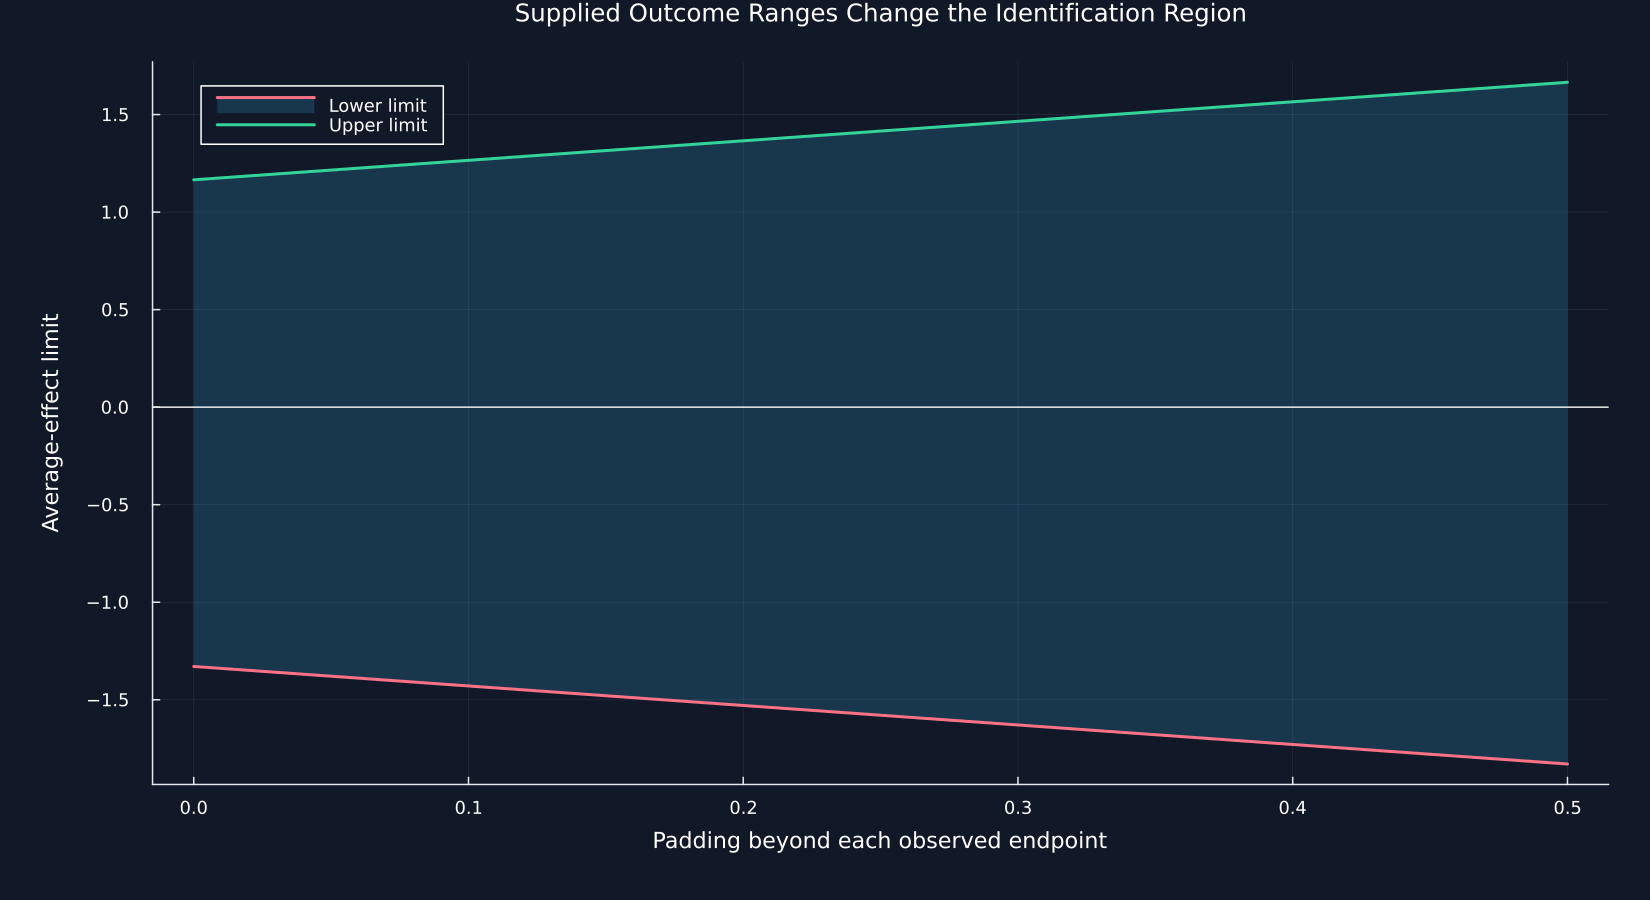

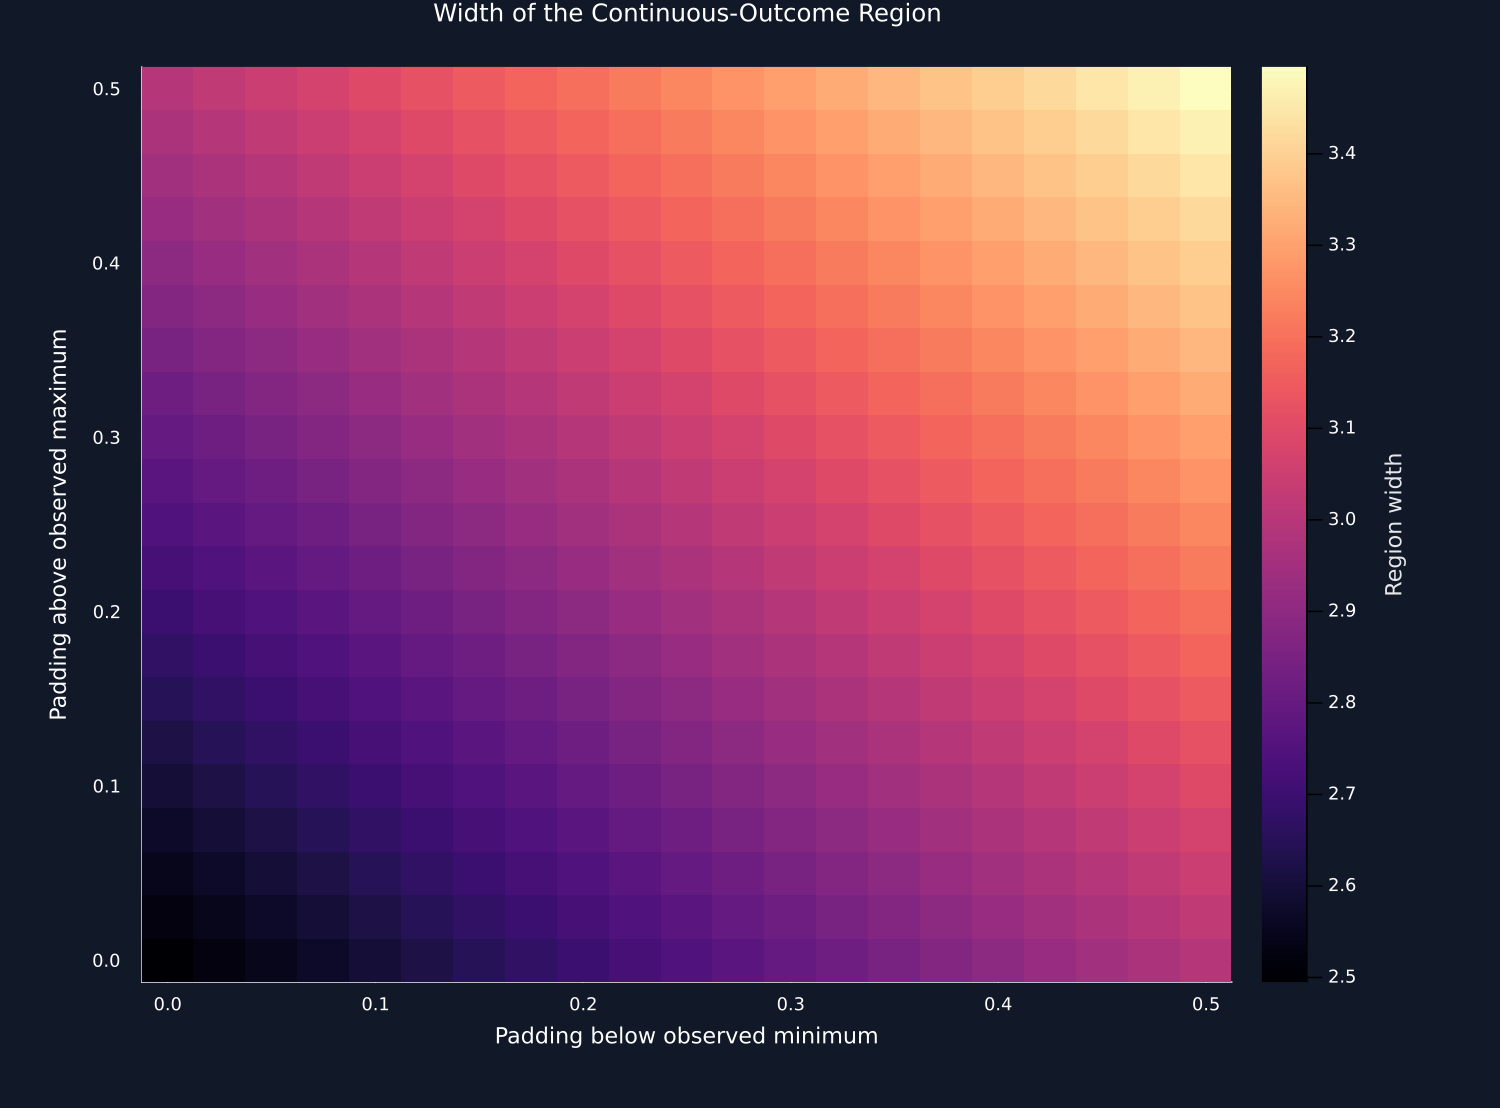

Row,Lower-end padding,Upper-end padding,Region width,Region midpoint
,Float64,Float64,Float64,Float64
1,0.0,0.0,2.49498,-0.0818856
2,0.0,0.5,2.99498,-0.0228856
3,0.5,0.0,2.99498,-0.140886
4,0.5,0.5,3.49498,-0.0818856


In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("05_partial_identification");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis: manski_ate_bounds
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSensitivityStudy.jl"))
using .BookSensitivityStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter05_random_inputs"),"sensitivity")
captions=Dict("manski_notation"=>"Notation for bounded-outcome identification.","manski_assumptions"=>"Assumptions and limits of the bounded-outcome calculation.","manski_exact_enumeration"=>"Extreme missing-potential-outcome enumeration for three units.","manski_exact_summary"=>"Exact comparison of released and enumerated limits.","manski_boundary_cases"=>"Boundary cases accepted by the released calculation.","manski_invalid_input_checks"=>"Invalid-input checks for the bounded-outcome calculation.","manski_outcome_range_sensitivity"=>"Identification limits as the supplied upper outcome limit changes.","mpdta_bound_provenance"=>"Provenance of the public panel used for the bounded-outcome example.","mpdta_binary_group_summary"=>"Public county outcomes by the fixed group indicator.","mpdta_binary_bounds"=>"Worst-case limits for the public binary county outcome.","manski_treatment_share_sweep"=>"Location of the binary-outcome limits as the treatment fraction changes.","manski_section_summary"=>"Summary of the bounded-outcome calculations.","sensitivity_notation"=>"Notation for regression sensitivity analysis.","sensitivity_generated_design"=>"Declared parameters of the controlled omitted-variable calculation.","sensitivity_generated_models"=>"Reduced, full, and sensitivity-adjusted exposure estimates.","sensitivity_generated_strengths"=>"Conditional strengths in the controlled calculation.","sensitivity_recovery_checks"=>"Recovery and zero-strength checks.","sensitivity_identity_cases"=>"Selected sensitivity calculations with supplied strengths.","mpdta_regression_models"=>"Descriptive public county regressions.","mpdta_regression_summary"=>"Public county sample used in the descriptive sensitivity calculation.","mpdta_observed_covariate_benchmarks"=>"Exact observed-covariate sensitivity benchmarks.","mpdta_observed_covariate_benchmarks_book"=>"Observed-covariate sensitivity benchmarks used in the chapter.","sensitivity_robustness_values"=>"Robustness values for the controlled and public calculations.","regions_notation"=>"Notation for identification and sensitivity regions.","regions_assumption_ledger"=>"Assumption ledger for the chapter calculations.","regions_public_bound_decomposition"=>"Treated and control contributions to the public binary-outcome limits.","regions_continuous_outcome_padding"=>"Effect limits under alternative supplied ranges for the public continuous outcome.","regions_width_surface_corners"=>"Corner cases from the outcome-range surface.","regions_sensitivity_sign_counts"=>"Grid counts on each side of the zero-estimate boundary.","regions_zero_estimate_frontier_points"=>"Selected finite points on the zero-estimate frontier.","regions_integration_checks"=>"Checks linking the identification and sensitivity calculations.","regions_section_summary"=>"How to interpret the chapter's identification and sensitivity regions.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim5-"*replace(name,"_"=>"-"))
    return nothing
end
function generated_sensitivity()
    values=normal_block(store,"generated")
    x,z,noise_d,noise_y=eachcol(values)
    d=.8 .*z+.3 .*x+noise_d
    y=2 .*d+1.4 .*z+x+noise_y
    reduced=sensitivity_ols(y,d,x)
    full=sensitivity_ols(y,d,x,z)
    d_reduced=sensitivity_ols(d,x)
    d_full=sensitivity_ols(d,x,z)
    return (;x,z,d,y,reduced,full,r2d=sensitivity_partial_r2(d_reduced,d_full),r2y=sensitivity_partial_r2(reduced,full))
end
notation = frame(["Symbol","Description"],[["I(L,U)","Identification region under supplied outcome limits"],["p","Fraction of units in the treated group"],["Mean observed Y among treated","Observed treated-group outcome mean"],["Mean observed Y among control","Observed control-group outcome mean"],["Lower tau","Lower endpoint of the empirical effect region"],["Upper tau","Upper endpoint of the empirical effect region"]])
table(notation,"regions_notation")
ledger = frame(["Calculation","Supplied information","Not supplied"],[["Worst-case effect region","Consistency and finite outcome limits","Exchangeability and sampling distribution"],["Regression sensitivity","Linear regression and two partial R-squared values","Identity or existence of an omitted variable"],["Observed-covariate benchmark","Measured baseline variables","Upper bound on all hidden confounding"],["Public county example","Fixed public outcomes and group labels","A defended causal assignment mechanism"]])
table(ledger,"regions_assumption_ledger")
raw,counties=sensitivity_counties()
y_binary,d_public=counties[:,8],counties[:,2]
p=mean(d_public)
treated_mean,control_mean=mean(y_binary[d_public.==1]),mean(y_binary[d_public.==0])
lower_treated,lower_control=p*(treated_mean-1),(1-p)*(0-control_mean)
upper_treated,upper_control=p*treated_mean,(1-p)*(1-control_mean)
decomposition=frame(["Endpoint","Treated contribution","Control contribution","Total"],[("Lower",lower_treated,lower_control,lower_treated+lower_control),("Upper",upper_treated,upper_control,upper_treated+upper_control)])
released_binary=manski_ate_bounds(y_binary,d_public;lower=0,upper=1)
@assert isapprox(decomposition[1,4],released_binary.lower)
@assert isapprox(decomposition[2,4],released_binary.upper)
table(decomposition,"regions_public_bound_decomposition")
y_change=counties[:,7]
observed_min,observed_max=extrema(y_change)
padding_frame=frame(["Padding beyond observed range","Lower outcome limit","Upper outcome limit","Lower effect limit","Upper effect limit","Region width"],[(padding,lower,upper,result.lower,result.upper,result.upper-result.lower) for padding in range(0,.5;length=11) for lower in (observed_min-padding,) for upper in (observed_max+padding,) for result in (manski_ate_bounds(y_change,d_public;lower,upper),)])
table(padding_frame,"regions_continuous_outcome_padding")
save_data(padding_frame,paths,"regions_continuous_outcome_padding")
figure=plot(padding_frame[:,1],padding_frame[:,4];fillrange=padding_frame[:,5],fillalpha=.18,fillcolor=palette.cyan,color=palette.rose,label="Lower limit",xlabel="Padding beyond each observed endpoint",ylabel="Average-effect limit",title="Supplied Outcome Ranges Change the Identification Region",size=(1100,600))
plot!(figure,padding_frame[:,1],padding_frame[:,5];color=palette.green,label="Upper limit")
hline!(figure,[0.];color=palette.text,linewidth=1,label="")
save_figure(figure,paths,"regions_continuous_outcome_padding")
lower_padding_values=collect(range(0,.5;length=21))
upper_padding_values=copy(lower_padding_values)
surface_frame=frame(["Lower-end padding","Upper-end padding","Region width","Region midpoint"],[(lower_padding,upper_padding,result.upper-result.lower,(result.lower+result.upper)/2) for lower_padding in lower_padding_values for upper_padding in upper_padding_values for result in (manski_ate_bounds(y_change,d_public;lower=observed_min-lower_padding,upper=observed_max+upper_padding),)])
save_data(surface_frame,paths,"regions_width_surface")
width_surface=reshape(surface_frame[:,3],21,21)
figure=heatmap(lower_padding_values,upper_padding_values,width_surface;color=:magma,xlabel="Padding below observed minimum",ylabel="Padding above observed maximum",title="Width of the Continuous-Outcome Region",colorbar_title="Region width",size=(1000,740),right_margin=14Plots.mm)
save_figure(figure,paths,"regions_width_surface")
surface_corners=surface_frame[in.(surface_frame[:,1],Ref((0.,.5))).&in.(surface_frame[:,2],Ref((0.,.5))),:]
table(surface_corners,"regions_width_surface_corners")


## Sign Regions in Regression Sensitivity

For a fixed reduced regression, each pair of partial R-squared values gives an adjusted exposure coefficient. The sign region is

$$
\mathcal S_{+}=\left\{(r_D,r_Y):\widehat\tau(r_D,r_Y)>0\right\},
$$

where $r_D=R^2_{D\sim Z\mid X}$ and $r_Y=R^2_{Y\sim Z\mid D,X}$. The boundary of this set marks combinations that move the adjusted estimate to zero. It is conditional on the linear sensitivity calculation, the reduced estimate, its standard error, and its residual degrees of freedom.

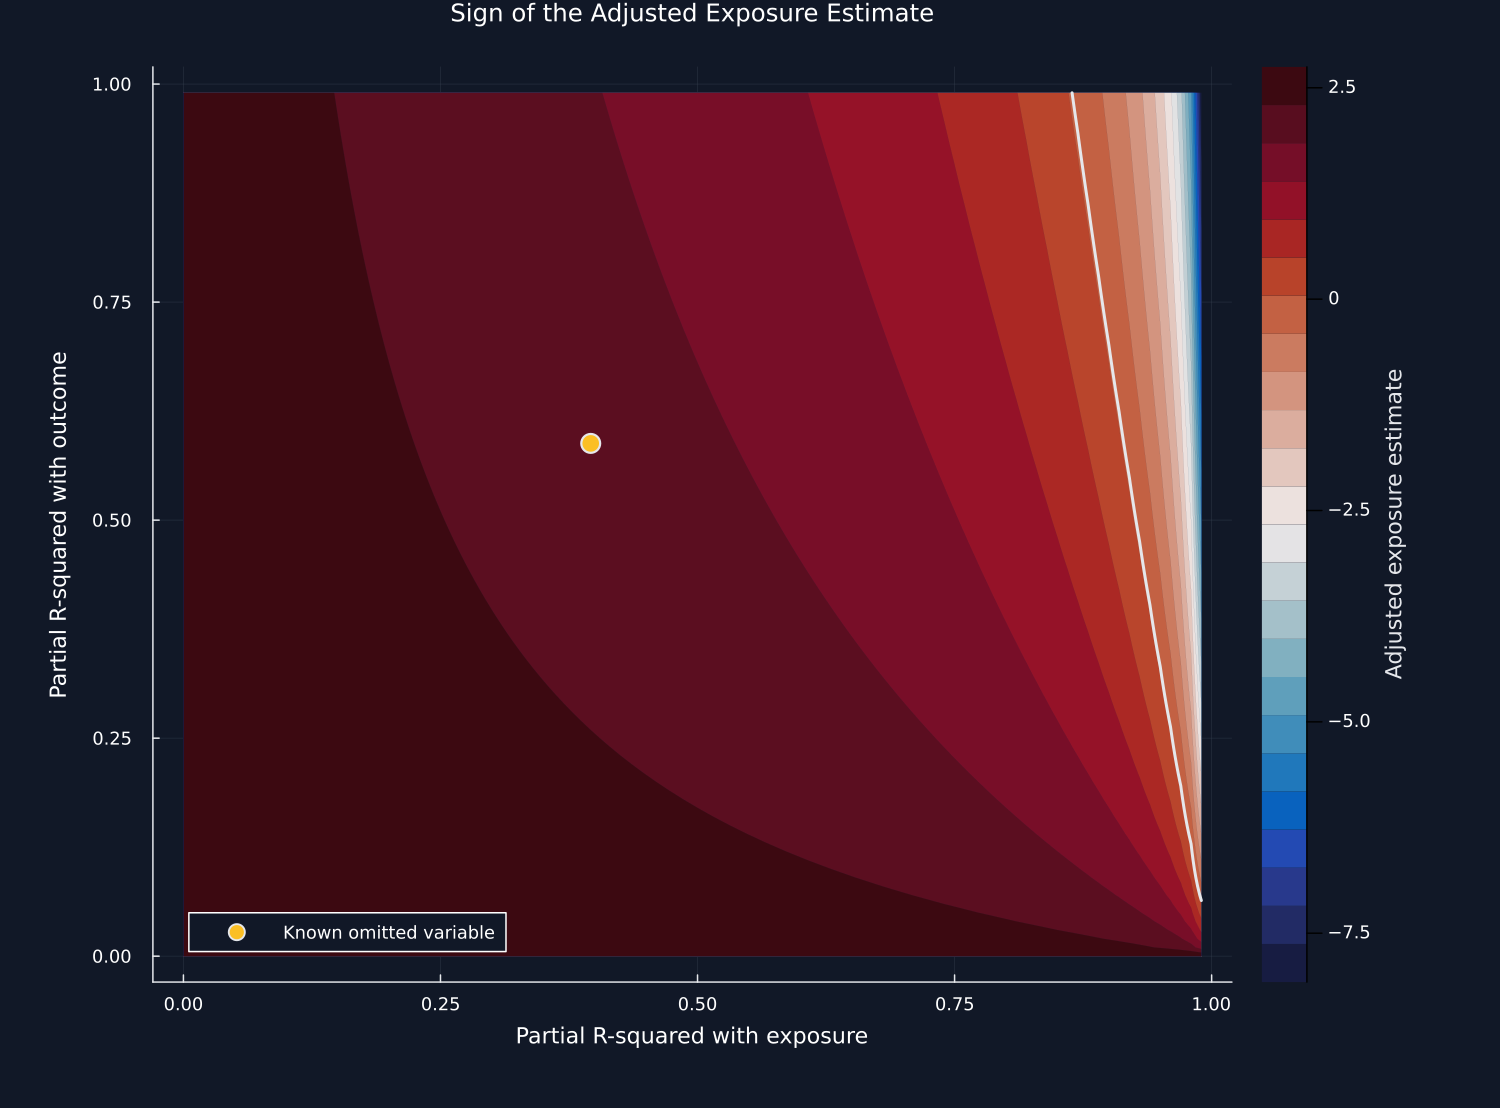

Row,Region,Grid points
,String,Int64
1,Zero or negative adjusted estimate,661
2,Positive adjusted estimate,9339


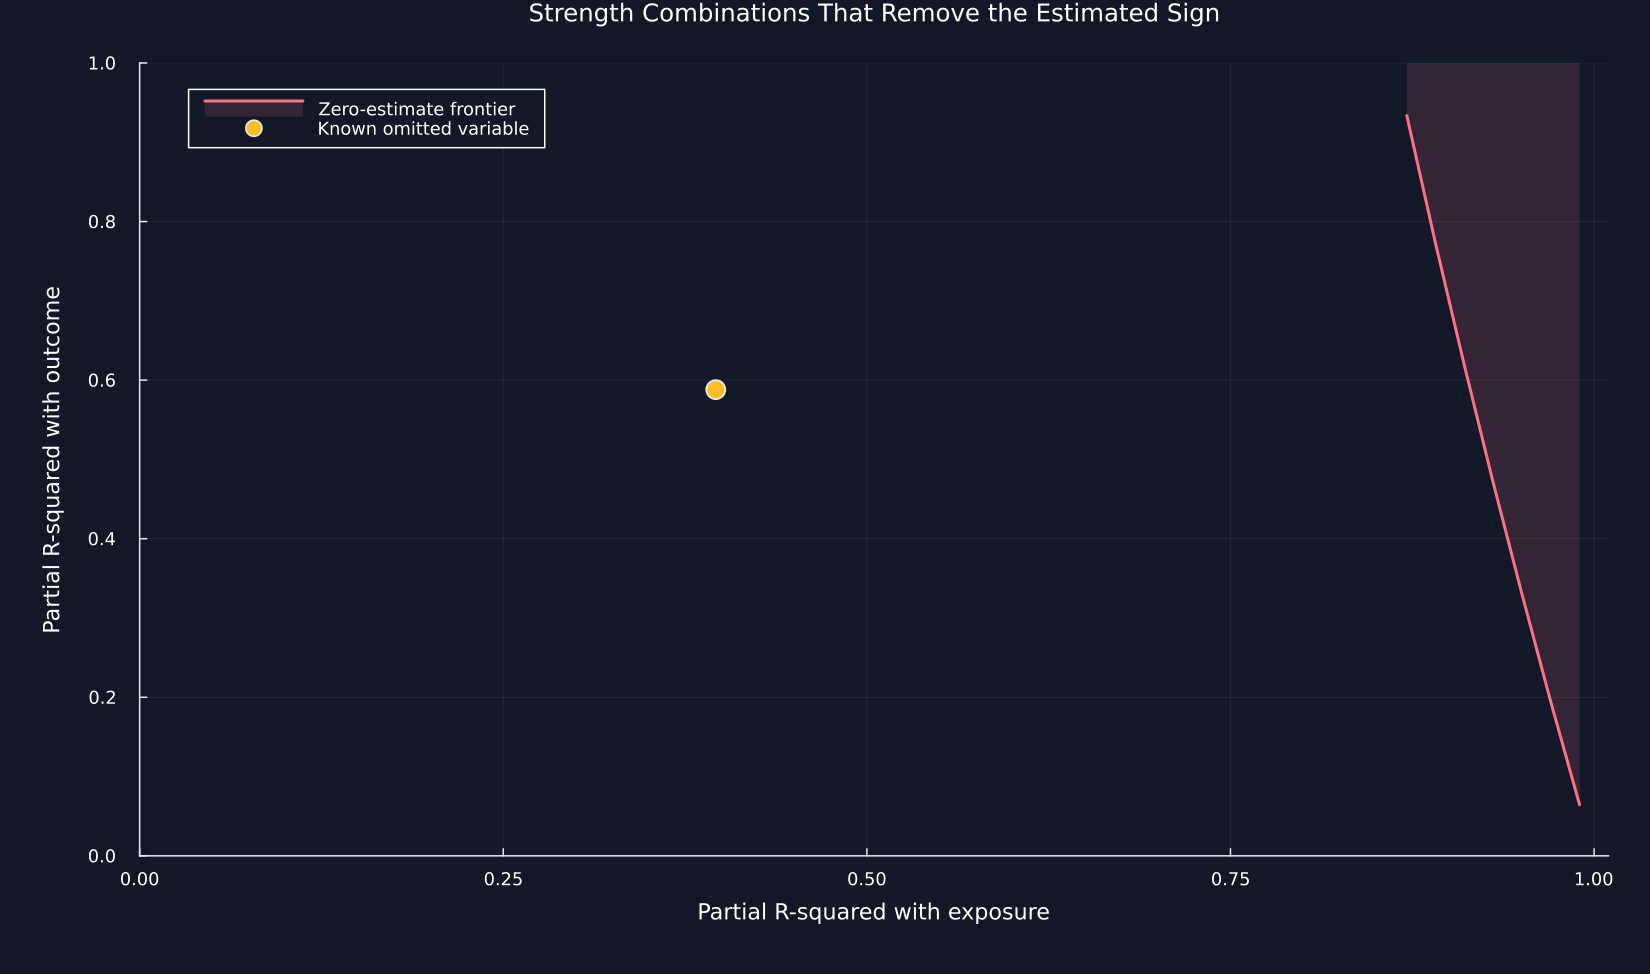

Row,Partial R-squared with exposure,Minimum partial R-squared with outcome
,Float64,Float64
1,0.871224,0.933514
2,0.89102,0.771982
3,0.910816,0.618378
4,0.930612,0.470721
5,0.950408,0.33
6,0.970204,0.194234
7,0.99,0.0644144


In [2]:
generated=generated_sensitivity()
reduced,full,known_r2d,known_r2y=generated.reduced,generated.full,generated.r2d,generated.r2y
strength_values=collect(range(0,.99;length=100))
sign_frame=frame(["Partial R-squared with exposure","Partial R-squared with outcome","Adjusted estimate","Positive estimate"],[(exposure,outcome,estimate,estimate>0) for exposure in strength_values for outcome in strength_values for estimate in (sensitivity_estimate(exposure,outcome,reduced.coefficients[2],reduced.errors[2],reduced.degrees),)])
save_data(sign_frame,paths,"regions_sensitivity_sign_map")
sign_surface=reshape(sign_frame[:,3],100,100)
levels=collect(range(minimum(sign_surface),maximum(sign_surface);length=25))
figure=contourf(strength_values,strength_values,sign_surface;levels,color=:balance,linewidth=0,xlabel="Partial R-squared with exposure",ylabel="Partial R-squared with outcome",title="Sign of the Adjusted Exposure Estimate",colorbar_title="Adjusted exposure estimate",size=(1000,740),right_margin=14Plots.mm,legend=:bottomleft)
contour!(figure,strength_values,strength_values,sign_surface;levels=[0.],color=palette.text,linewidth=2,colorbar_entry=false,label="")
scatter!(figure,[known_r2d],[known_r2y];color=palette.amber,markerstrokecolor=palette.text,markersize=7,label="Known omitted variable")
save_figure(figure,paths,"regions_sensitivity_sign_map")
sign_summary=frame(["Region","Grid points"],[(positive ? "Positive adjusted estimate" : "Zero or negative adjusted estimate",count(==(positive),sign_frame[:,4])) for positive in (false,true)])
table(sign_summary,"regions_sensitivity_sign_counts")
frontier_records=[]
outcome_grid=collect(range(0,.99;length=1000))
for exposure in range(.02,.99;length=50)
    estimates=[sensitivity_estimate(exposure,outcome,reduced.coefficients[2],reduced.errors[2],reduced.degrees) for outcome in outcome_grid]
    crossing=findfirst(<=(0),estimates)
    push!(frontier_records,(exposure,isnothing(crossing) ? NaN : outcome_grid[crossing]))
end
frontier=frame(["Partial R-squared with exposure","Minimum partial R-squared with outcome"],frontier_records)
save_data(frontier,paths,"regions_zero_estimate_frontier")
figure=plot(frontier[:,1],frontier[:,2];fillrange=1,fillalpha=.15,color=palette.rose,label="Zero-estimate frontier",xlabel="Partial R-squared with exposure",ylabel="Partial R-squared with outcome",title="Strength Combinations That Remove the Estimated Sign",xlims=(0,1.01),ylims=(0,1),size=(1100,650),legend=:topleft)
scatter!(figure,[known_r2d],[known_r2y];color=palette.amber,markerstrokecolor=palette.text,markersize=7,label="Known omitted variable")
save_figure(figure,paths,"regions_zero_estimate_frontier")
finite_frontier=frontier[isfinite.(frontier[:,2]),:]
frontier_indices=unique(floor.(Int,collect(range(0,nrow(finite_frontier)-1;length=min(10,nrow(finite_frontier))))).+1)
frontier_table=finite_frontier[frontier_indices,:]
table(frontier_table,"regions_zero_estimate_frontier_points")


## Reading the Regions Together

The bounded-outcome region and the regression sensitivity surface answer different questions. The first varies missing potential outcomes within a supplied outcome range and does not assume treatment exchangeability. The second starts from a linear regression and varies the conditional strength of one omitted variable. A narrow regression interval does not narrow the worst-case identification region, and a wide identification region does not determine which omitted-variable strengths are plausible.

In [3]:
integration_checks=frame(["Statement","Pass"],[("Binary public outcome lies inside supplied limits",minimum(y_binary)>=0 && maximum(y_binary)<=1),("Released binary limits equal group decomposition",isapprox(released_binary.lower,decomposition[1,4]) && isapprox(released_binary.upper,decomposition[2,4])),("Continuous-region width equals supplied outcome range",all(isapprox.(padding_frame[:,6],padding_frame[:,3]-padding_frame[:,2]))),("Known omitted-variable adjustment recovers full coefficient",isapprox(sensitivity_estimate(known_r2d,known_r2y,reduced.coefficients[2],reduced.errors[2],reduced.degrees),full.coefficients[2]))])
@assert all(integration_checks.Pass)
table(integration_checks,"regions_integration_checks")
section_summary = frame(["Object","Changes when","Does not establish"],[["Worst-case identification region","The supplied outcome limits change","A point effect or confidence interval"],["Regression sensitivity surface","The two partial R-squared values change","That a hidden variable with those strengths exists"],["Observed-covariate benchmark","A measured baseline variable is omitted","A bound on all unmeasured confounding"],["Public county calculation","The declared outcome, group, or controls change","A causal minimum-wage effect"]])
table(section_summary,"regions_section_summary")


Row,Statement,Pass
,String,String
1,Binary public outcome lies inside supplied limits,Pass
2,Released binary limits equal group decomposition,Pass
3,Continuous-region width equals supplied outcome range,Pass
4,Known omitted-variable adjustment recovers full coefficient,Pass


Row,Object,Changes when,Does not establish
,String,String,String
1,Worst-case identification region,The supplied outcome limits change,A point effect or confidence interval
2,Regression sensitivity surface,The two partial R-squared values change,That a hidden variable with those strengths exists
3,Observed-covariate benchmark,A measured baseline variable is omitted,A bound on all unmeasured confounding
4,Public county calculation,"The declared outcome, group, or controls change",A causal minimum-wage effect
